# Boston House Price Prediction

## Project Overview

This notebook develops and evaluates regression models for predicting Boston house prices. It follows a reproducible workflow: load and understand the data, clean missing values, explore patterns, prepare train and test data, train several regression algorithms, compare their results, and select a final model.

The Python code and results are kept unchanged; the Markdown cells explain the purpose and interpretation of each stage.


## Imports and Libraries

The next code cell imports the libraries used throughout the project. pandas handles tabular data, Matplotlib and Seaborn create visualizations, and scikit-learn provides preprocessing tools, regression models, train-test splitting, and evaluation metrics.


In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


## 1. Load the Dataset

The next cell reads `HousingData.csv` into a pandas DataFrame and displays sample rows. Loading the data is the first step because all later inspection, cleaning, visualization, and modeling operations use this DataFrame.


In [ ]:
data = pd.read_csv("HousingData.csv")
print(data.head(10))

      CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31   0.0  0.538  6.575   65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07   0.0  0.469  6.421   78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07   0.0  0.469  7.185   61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18   0.0  0.458  6.998   45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18   0.0  0.458  7.147   54.2  6.0622    3  222     18.7   
5  0.02985   0.0   2.18   0.0  0.458  6.430   58.7  6.0622    3  222     18.7   
6  0.08829  12.5   7.87   NaN  0.524  6.012   66.6  5.5605    5  311     15.2   
7  0.14455  12.5   7.87   0.0  0.524  6.172   96.1  5.9505    5  311     15.2   
8  0.21124  12.5   7.87   0.0  0.524  5.631  100.0  6.0821    5  311     15.2   
9  0.17004  12.5   7.87   NaN  0.524  6.004   85.9  6.5921    5  311     15.2   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.6

**Interpretation:** The displayed records confirm that the file contains the housing predictors and the `MEDV` target column. The data is ready for structural inspection.


## 2. Understand the Dataset Structure

This cell reports the column names, number of values, shape, data types, non-null counts, and summary statistics. These checks establish what each analysis will work with and reveal missing values or unusual ranges before any preprocessing.


In [24]:
print(f"Columns names : {data.columns}")
print("\n")
print(f"Size : {data.size}",)
print("\n")
print(f"Shape : {data.shape}")
print("\n")
print(f"INFO : {data.info()}")
print("\n")
print(f"describe : {data.describe()}")

Columns names : Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='str')


Size : 7084


Shape : (506, 14)


<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB
INFO : None


describe :              CRIM          ZN 

**Interpretation:** The dataset contains **506 rows and 14 columns**. It has 13 predictors and the `MEDV` target. Some columns have fewer than 506 non-null values, confirming that missing-data treatment is needed.


## 3. Check Duplicates and Missing Values

This cell checks for duplicate rows and counts missing values in each column. Duplicate records can give some observations too much influence, while missing values can cause errors or biased model training if they are not handled.


In [28]:
print("Duplicate rows:", data.duplicated().sum())

print("Unique rows:", data.drop_duplicates().shape[0])

print("Missing values:\n", data.isnull().sum())

Duplicate rows: 0
Unique rows: 506
Missing values:
 CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64


**Interpretation:** There are **0 duplicate rows**. Missing values occur in `CRIM`, `ZN`, `INDUS`, `CHAS`, `AGE`, and `LSTAT`, with **20 missing values in each**.


## 4. Quantify Missing Data

The next cell converts missing-value counts into percentages and summarizes the affected variables. Percentages make the scale of the data-quality issue easier to compare across columns and help justify an appropriate imputation strategy.


In [30]:
missing_percentage = (data.isnull().sum() / len(data)) * 100

print(missing_percentage[missing_percentage > 0])

data[['CRIM', 'ZN', 'INDUS', 'CHAS', 'AGE', 'LSTAT']].describe()

CRIM     3.952569
ZN       3.952569
INDUS    3.952569
CHAS     3.952569
AGE      3.952569
LSTAT    3.952569
dtype: float64


,CRIM,ZN,INDUS,CHAS,AGE,LSTAT
count,486.000000,486.000000,486.000000,486.000000,486.000000,486.000000
mean,3.611874,11.211934,11.083992,0.069959,68.518519,12.715432
std,8.720192,23.388876,6.835896,0.255340,27.999513,7.155871
min,0.006320,0.000000,0.460000,0.000000,2.900000,1.730000
25%,0.081900,0.000000,5.190000,0.000000,45.175000,7.125000
50%,0.253715,0.000000,9.690000,0.000000,76.800000,11.430000
75%,3.560263,12.500000,18.100000,0.000000,93.975000,16.955000
max,88.976200,100.000000,27.740000,1.000000,100.000000,37.970000


**Interpretation:** Each affected column has **3.95% missing values**. The missingness is limited and consistently measured, so the notebook uses median imputation for numeric variables and mode imputation for `CHAS`.


## 5. Inspect the Binary `CHAS` Feature

`CHAS` indicates whether a tract borders the Charles River. The next cells examine its counts and proportions because binary features can be imbalanced, and the most frequent category is also used to fill its missing values.


In [ ]:
data['CHAS'].value_counts()

CHAS
0.0    93.004115
1.0     6.995885
Name: proportion, dtype: float64

The next cell expresses the same `CHAS` distribution as percentages, making the imbalance easier to interpret relative to the full dataset.


In [41]:
data['CHAS'].value_counts(normalize=True) * 100

CHAS
0.0    93.004115
1.0     6.995885
Name: proportion, dtype: float64

**Interpretation:** `CHAS` contains **93.00%** zeros and **7.00%** ones. This is an imbalanced binary feature, so its distribution should be kept in mind when interpreting models.


## 6. Clean Missing Values

The next cell fills missing values in the numeric columns with each column's median. It fills missing `CHAS` values with the mode, or most frequent category. Median imputation is less sensitive to extreme values than the mean, while mode imputation preserves the binary feature's categories.


In [42]:
median_cols = ['CRIM', 'ZN', 'INDUS', 'AGE', 'LSTAT']

for col in median_cols:
    data[col] = data[col].fillna(data[col].median())

data['CHAS'] = data['CHAS'].fillna(data['CHAS'].mode()[0])

The following check verifies that the imputation step produced a complete DataFrame before continuing with EDA.


In [43]:
print(data.isnull().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


**Interpretation:** Every column now reports **0 missing values**, so the initial data-cleaning step completed successfully.


## 7. Confirm Data Integrity After Cleaning

This cell rechecks the shape and duplicate count after preprocessing. It confirms that cleaning did not remove rows, add duplicates, or change the overall dataset dimensions.


In [44]:
print("Dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())

Dataset shape: (506, 14)
Duplicate rows: 0


**Interpretation:** The cleaned dataset remains **506 ? 14** and still contains **0 duplicate rows**.


# Exploratory Data Analysis

## 8. Analyze the Target Variable

`MEDV` is the target variable: the median value of owner-occupied homes. Understanding its center, spread, and range helps define the prediction problem and provides a baseline for judging model errors.


In [49]:
data['MEDV'].describe()

count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64

**Interpretation:** `MEDV` has a mean of **22.53**, a median of **21.20**, a standard deviation of **9.20**, and a range from **5.0 to 50.0**.


## 9. Visualize the House-Price Distribution

The histogram and kernel density estimate show how the target values are distributed. This helps identify concentration, skewness, or multiple high- or low-price regions that may not be obvious from summary statistics alone.


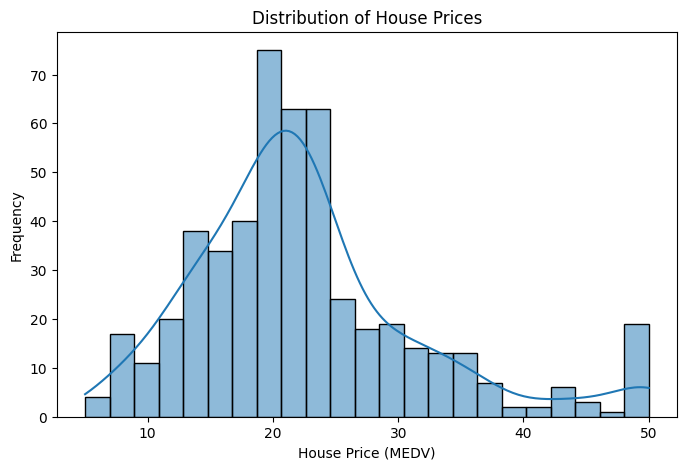

In [50]:
plt.figure(figsize=(8, 5))
sns.histplot(data['MEDV'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price (MEDV)')
plt.ylabel('Frequency')

plt.show()

**Interpretation:** This visualization complements the numerical summary by showing the observed shape and concentration of `MEDV`; no values are removed based on the plot alone.


## 10. Inspect the Target Range and Upper Limit

This cell prints the minimum and maximum target values and counts how many houses have the maximum. Repeated maximum values can indicate that the target has an upper recording limit, which is important when interpreting predictions near that value.


In [51]:
print("Minimum price:", data['MEDV'].min())
print("Maximum price:", data['MEDV'].max())

print("Number of houses at maximum price:",
      (data['MEDV'] == data['MEDV'].max()).sum())

Minimum price: 5.0
Maximum price: 50.0
Number of houses at maximum price: 16


**Interpretation:** The minimum price is **5.0**, the maximum is **50.0**, and **16 houses** have the maximum value of 50.0.


## 11. Visualize Potential Outliers

The boxplot summarizes the median, quartiles, overall spread, and unusually distant `MEDV` values. It provides a visual check before calculating outliers numerically with the interquartile range rule.


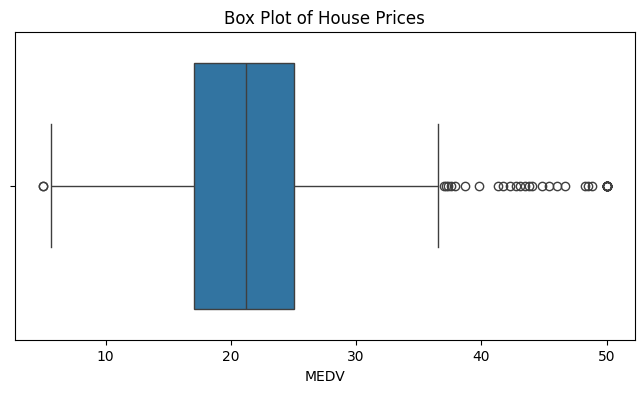

In [52]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=data['MEDV'])

plt.title('Box Plot of House Prices')
plt.xlabel('MEDV')

plt.show()

**Interpretation:** The boxplot highlights the spread of house prices and possible extreme observations. These observations are investigated rather than removed automatically.


## 12. Detect Outliers with the IQR Rule

The interquartile range (IQR) is the distance between the first and third quartiles. Values below `Q1 - 1.5 ? IQR` or above `Q3 + 1.5 ? IQR` are flagged as potential outliers. This is a screening rule, not proof that a record is incorrect.


In [53]:
Q1 = data['MEDV'].quantile(0.25)
Q3 = data['MEDV'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[
    (data['MEDV'] < lower) |
    (data['MEDV'] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower)
print("Upper boundary:", upper)
print("Number of outliers:", len(outliers))

Q1: 17.025
Q3: 25.0
IQR: 7.975000000000001
Lower boundary: 5.0624999999999964
Upper boundary: 36.962500000000006
Number of outliers: 40


**Interpretation:** The lower and upper IQR boundaries are **5.06** and **36.96**, producing **40 potential outliers**. They should be investigated in context because unusual houses may still be valid observations.


The next cell displays selected predictors for the flagged records. Comparing `RM`, `LSTAT`, and `PTRATIO` with `MEDV` gives context for the unusually low or high prices.


In [54]:
print(outliers[['RM', 'LSTAT', 'PTRATIO', 'MEDV']].sort_values('MEDV'))

        RM  LSTAT  PTRATIO  MEDV
405  5.683  22.98     20.2   5.0
398  5.453  30.59     20.2   5.0
190  6.951   5.10     15.2  37.0
179  6.980   5.04     17.8  37.2
291  7.148   3.56     19.2  37.3
226  8.040  11.43     17.4  37.6
182  7.155   4.82     17.8  37.9
97   8.069   4.21     18.0  38.7
180  7.765   7.56     17.8  39.8
157  6.943   4.59     14.7  41.3
232  8.337   2.47     17.4  41.7
202  7.610   3.11     14.7  42.3
253  8.259   3.54     19.1  42.8
261  7.520   7.26     13.0  43.1
268  7.470   3.16     13.0  43.5
98   7.820   3.57     18.0  43.8
256  7.454   3.11     15.9  44.0
224  8.266   4.14     17.4  44.8
280  7.820   3.76     14.9  45.4
282  7.645   3.01     14.9  46.0
228  7.686  11.43     17.4  46.7
233  8.247   3.95     17.4  48.3
203  7.853   3.81     14.7  48.5
262  8.398   5.91     13.0  48.8
204  8.034   2.88     14.7  50.0
195  7.875   2.97     14.4  50.0
186  7.831   4.45     17.8  50.0
166  7.929   3.70     14.7  50.0
225  8.725   4.63     17.4  50.0
161  7.489

**Interpretation:** The table provides feature-level context for the flagged target values. The notebook keeps these records for modeling instead of deleting them based only on the IQR rule.


## 13. Correlation Analysis

Correlation measures the strength and direction of a linear association between two numeric variables. The next cell ranks all feature correlations with `MEDV` to identify relationships worth exploring; correlation does not establish causation.


In [55]:
correlation = data.corr()

print(correlation['MEDV'].sort_values(ascending=False))

MEDV       1.000000
RM         0.695360
ZN         0.362292
B          0.333461
DIS        0.249929
CHAS       0.183844
AGE       -0.377572
RAD       -0.381626
CRIM      -0.383895
NOX       -0.427321
TAX       -0.468536
INDUS     -0.476394
PTRATIO   -0.507787
LSTAT     -0.723093
Name: MEDV, dtype: float64


**Interpretation:** `RM` has the strongest positive correlation with `MEDV` (**0.695**). `LSTAT` has the strongest negative correlation (**-0.723**), followed by `PTRATIO` (**-0.508**). These values identify associations, not causal effects.


## 14. Visualize the Correlation Matrix

The heatmap presents pairwise correlations using color and numeric annotations. It makes both the direction and relative strength of relationships easier to compare across the full dataset.


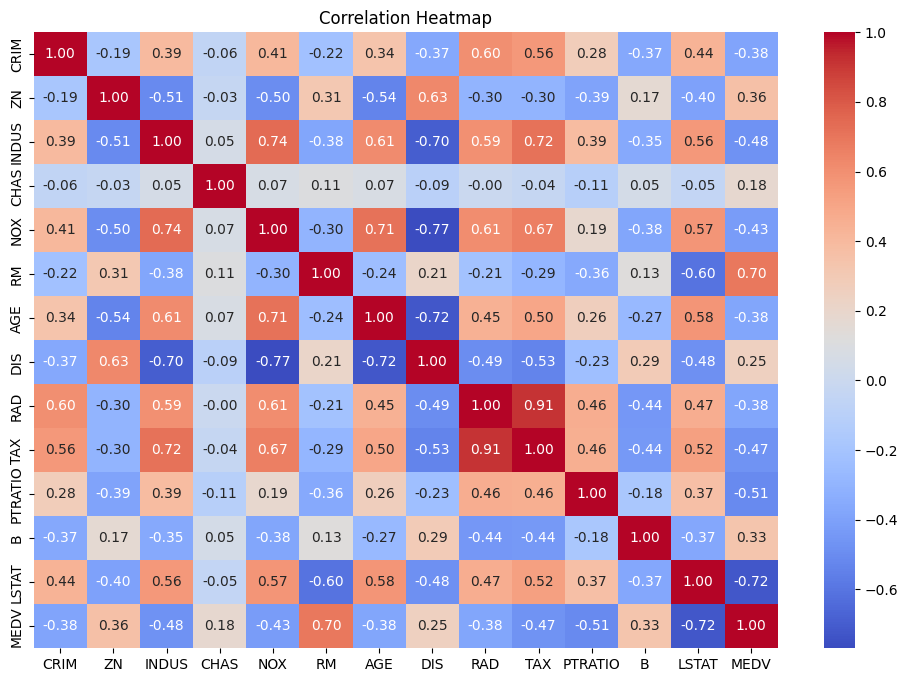

In [56]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

**Interpretation:** The heatmap provides a visual summary of the same pairwise relationships and helps identify groups of features that may contain overlapping information.


## 15. Visualize the Strongest Target Relationships

These scatter plots compare `MEDV` with `RM`, `LSTAT`, and `PTRATIO`, the features with the strongest observed target associations. Scatter plots show the pattern and spread of individual observations, not just one correlation number.


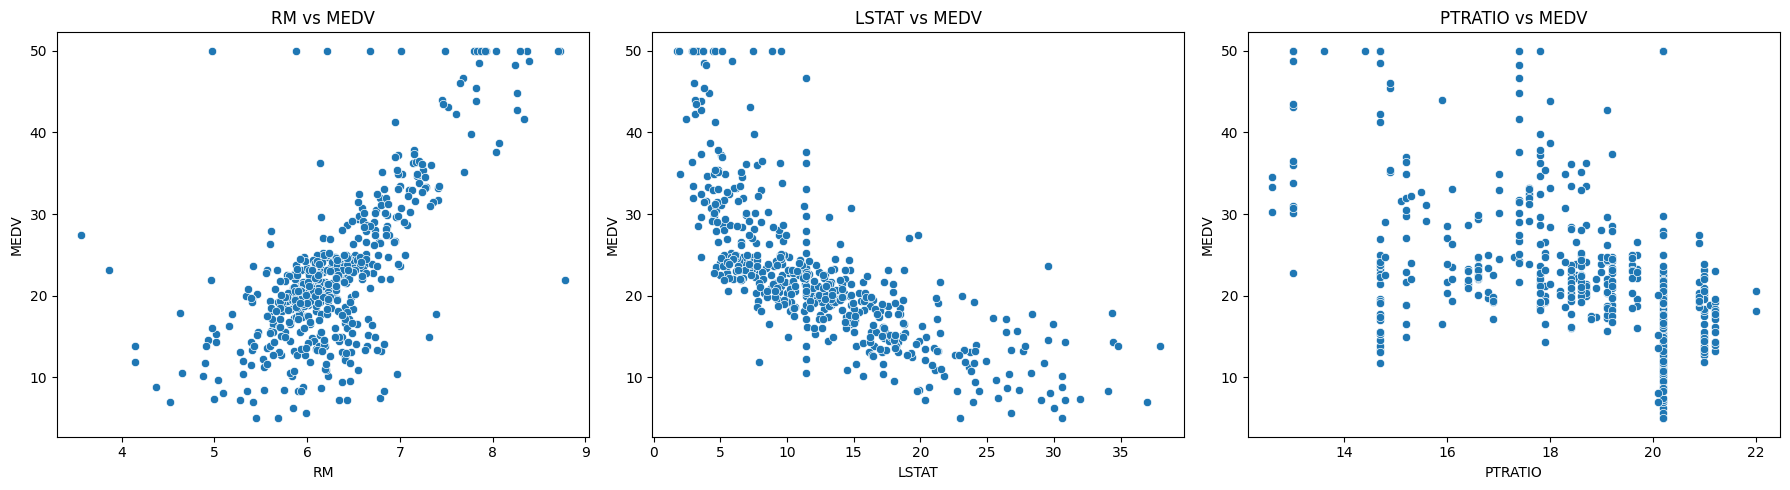

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=data, x='RM', y='MEDV', ax=axes[0])
axes[0].set_title('RM vs MEDV')

sns.scatterplot(data=data, x='LSTAT', y='MEDV', ax=axes[1])
axes[1].set_title('LSTAT vs MEDV')

sns.scatterplot(data=data, x='PTRATIO', y='MEDV', ax=axes[2])
axes[2].set_title('PTRATIO vs MEDV')

plt.tight_layout()
plt.show()

**Interpretation:** The plots provide record-level evidence for the relationships identified numerically: price varies with room count, lower-status percentage, and pupil-teacher ratio. The patterns are associations and may not be perfectly linear.


## 16. Inspect Feature-to-Feature Correlations

This heatmap excludes `MEDV` and focuses on relationships among predictors. Strong predictor-to-predictor correlations can indicate multicollinearity, where multiple variables carry similar information, which is especially relevant for interpreting linear models.


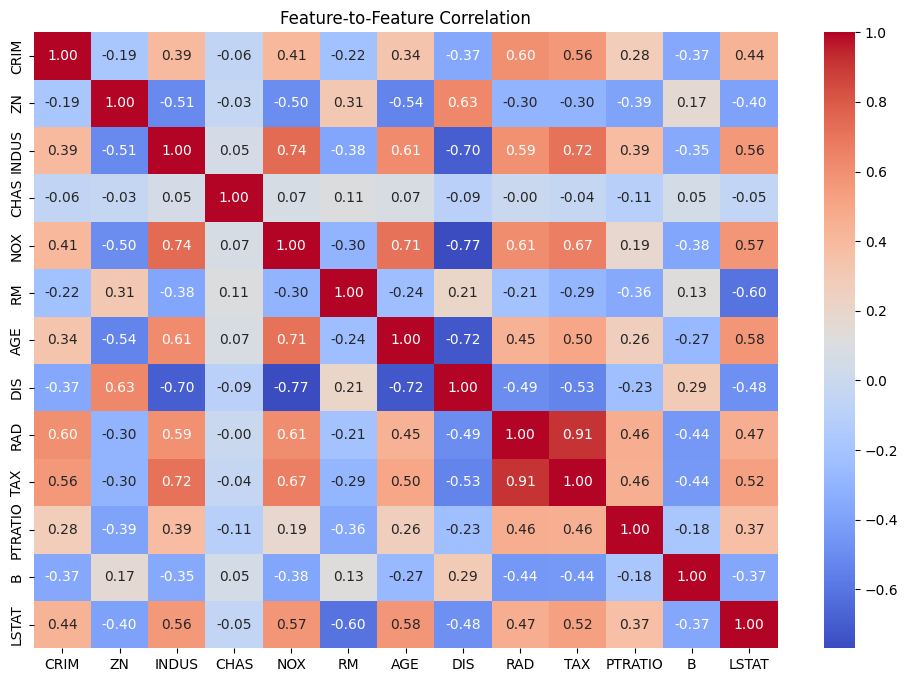

In [58]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    data.drop(columns='MEDV').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature-to-Feature Correlation')
plt.show()

**Interpretation:** The feature-only heatmap helps identify related predictors before modeling. Tree-based models can often handle such relationships more flexibly, while linear-model interpretation may be affected by them.


# Model Preparation

## 17. Separate Features and Target

The next cell creates `X`, containing the 13 input features, and `y`, containing `MEDV`. Separating predictors from the target ensures that models learn from housing characteristics without using the answer column as an input.


In [59]:
X = data.drop('MEDV', axis=1)
y = data['MEDV']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (506, 13)
Target shape: (506,)


**Interpretation:** `X` contains the model inputs and `y` contains the values the models must predict. The printed shapes confirm the separation.


## 18. Split Data into Training and Testing Sets

A train-test split reserves part of the data for an unbiased final check. The models learn from the training set and are evaluated on the unseen test set. Here, `test_size=0.2` reserves 20% for testing, and `random_state=42` makes the split reproducible.


In [60]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (404, 13)
X_test: (102, 13)
y_train: (404,)
y_test: (102,)


**Interpretation:** The split creates **404 training rows** and **102 testing rows**. The test data is kept separate from model fitting so the evaluation reflects performance on unseen records.


## 19. Prepare Imputation for the Modeling Split

This cell creates separate imputers for numeric and categorical-style values. The median imputer is used for numeric predictors, while the most-frequent imputer is used for `CHAS`. Fitting preprocessing on the training data avoids using test-set information during training.


In [61]:

median_imputer = SimpleImputer(strategy='median')
mode_imputer = SimpleImputer(strategy='most_frequent')

The next cell applies the fitted imputers to the training and testing predictors. The same learned replacements are used for both sets so the test data is transformed consistently.


In [ ]:
numerical_columns = X_train.drop(columns=['CHAS']).columns

X_train[numerical_columns] = median_imputer.fit_transform(
    X_train[numerical_columns])

X_train[['CHAS']] = mode_imputer.fit_transform(
    X_train[['CHAS']])

X_test[numerical_columns] = median_imputer.transform(
    X_test[numerical_columns])

X_test[['CHAS']] = mode_imputer.transform(
    X_test[['CHAS']])

This verification checks that the modeling matrices contain no missing values before any model is trained.


In [63]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


**Interpretation:** Both `X_train` and `X_test` contain **0 missing values**, so the predictors are ready for regression models.


# Regression Models

## 20. Linear Regression

Linear Regression estimates a weighted sum of the input features. It is a useful baseline because it is simple and interpretable, and its performance shows how well a linear relationship represents this dataset.


In [65]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


**Interpretation:** The model trained successfully. The intercept and coefficients quantify the fitted linear relationship between the predictors and house price.


The next cell displays the fitted intercept and coefficient for each feature. A coefficient represents the expected change in the prediction for a one-unit feature change when the other features are held constant, subject to the model's linear assumptions.


In [66]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X_train.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 28.16795337495866

Coefficients:
CRIM : -0.11257399303307113
ZN : 0.028179365282296545
INDUS : -0.02565590768913376
CHAS : 3.279482153006603
NOX : -15.978338344572334
RM : 4.717140255760028
AGE : -0.01818996389197624
DIS : -1.5062191711444712
RAD : 0.21821688085958704
TAX : -0.009054445374985523
PTRATIO : -0.89000954327874
B : 0.01203293820787052
LSTAT : -0.44416676404183025


**Interpretation:** The coefficients describe the direction and size of the fitted linear associations. They should be interpreted with care because feature scales and correlations differ.


The model now predicts prices for the held-out test set. Predictions are generated without refitting the model on the test data.


In [ ]:
y_pred = model.predict(X_test)

print("First 10 predicted prices:")
print(y_pred[:10])

First 10 predicted prices:
[29.02290756 36.51654453 14.53930169 25.0600581  18.39672661 23.02888283
 17.96715788 14.58282951 22.08280431 20.85618117]


This table compares a sample of actual test prices with the corresponding Linear Regression predictions.


In [68]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

print(comparison.head(10))

     Actual Price  Predicted Price
173          23.6        29.022908
274          32.4        36.516545
491          13.6        14.539302
72           22.8        25.060058
452          16.1        18.396727
76           20.0        23.028883
316          17.8        17.967158
140          14.0        14.582830
471          19.6        22.082804
500          16.8        20.856181


## 21. Evaluate Linear Regression

The evaluation uses three common regression metrics. **MAE** is the average absolute prediction error, **MSE** is the average squared error and penalizes large mistakes more strongly, and **R?** measures the proportion of target variance explained by the model (higher is better).


In [69]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 3.1487373170237802
Mean Squared Error: 24.999384790103544
R2 Score: 0.6591013893903486


**Interpretation:** Linear Regression records **MAE 3.149**, **MSE 24.999**, and **R? 0.659** on the test set. These values establish the baseline for the nonlinear models.


The actual-versus-predicted plot compares test prices with Linear Regression predictions. The dashed diagonal represents perfect predictions; points closer to it indicate smaller errors.


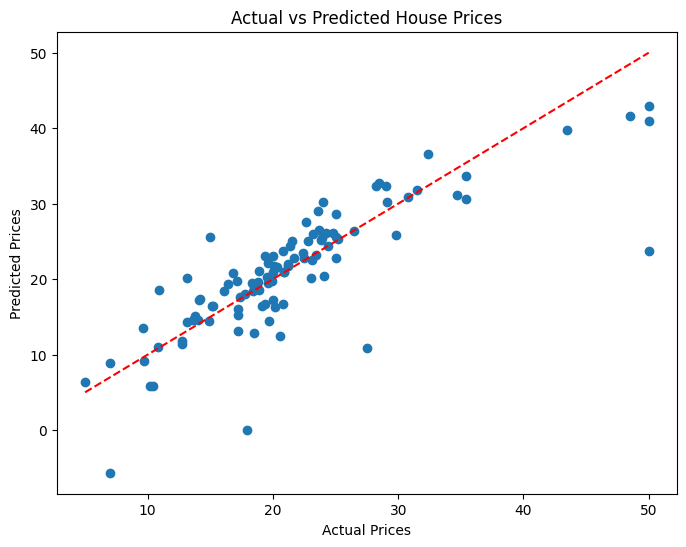

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

**Interpretation:** Deviations from the diagonal show prediction error. This plot complements MAE, MSE, and R? by showing where predictions differ from actual prices.


## 22. Decision Tree Regression

A Decision Tree Regressor splits the feature space into smaller regions and predicts a value for each region. It can model nonlinear relationships and interactions without requiring a straight-line relationship between every feature and the target.


In [71]:

tree_model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

The next cell fits the configured decision tree on the training data.


In [72]:
tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

The trained tree predicts prices for the test set.


In [76]:
tree_pred = tree_model.predict(X_test)
print(tree_pred[:10])

[22.05248619 27.90416667 19.81333333 27.90416667 16.24153846 22.05248619
 16.24153846 16.24153846 22.05248619 22.05248619]


This comparison table shows actual prices beside Decision Tree predictions for a sample of test records.


In [77]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': tree_pred
})

print(comparison.head(10))

     Actual Price  Predicted Price
173          23.6        22.052486
274          32.4        27.904167
491          13.6        19.813333
72           22.8        27.904167
452          16.1        16.241538
76           20.0        22.052486
316          17.8        16.241538
140          14.0        16.241538
471          19.6        22.052486
500          16.8        22.052486


The Decision Tree is evaluated using the same MAE, MSE, and R? definitions used for Linear Regression, allowing a fair comparison.


In [78]:

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Results")
print("MAE:", tree_mae)
print("MSE:", tree_mse)
print("R2 Score:", tree_r2)

Decision Tree Results
MAE: 2.7776384433978976
MSE: 12.420085444693727
R2 Score: 0.8306362373595151


**Interpretation:** Decision Tree Regression achieves **MAE 2.778**, **MSE 12.420**, and **R? 0.831**, improving substantially on the linear baseline.


## 23. Gradient Boosting Regression

Gradient Boosting builds a sequence of small decision trees. Each new tree focuses on correcting errors made by the previous trees, allowing the ensemble to model complex patterns while combining many weak learners.


In [79]:

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

gb_model.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

The fitted Gradient Boosting model generates predictions for the unseen test data.


In [81]:
gb_pred = gb_model.predict(X_test)
print(gb_pred[:10])

[23.15074454 30.85008911 16.67916398 23.41819433 16.37794842 21.73216118
 18.58970195 14.93609365 20.2041372  21.23356635]


This table compares actual and predicted prices for Gradient Boosting.


In [83]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': gb_pred
})

print(comparison.head(10))

     Actual Price  Predicted Price
173          23.6        23.150745
274          32.4        30.850089
491          13.6        16.679164
72           22.8        23.418194
452          16.1        16.377948
76           20.0        21.732161
316          17.8        18.589702
140          14.0        14.936094
471          19.6        20.204137
500          16.8        21.233566


The model is evaluated with MAE, MSE, and R? so it can be compared directly with the earlier models.


In [82]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Results")
print("MAE:", gb_mae)
print("MSE:", gb_mse)
print("R2 Score:", gb_r2)

Gradient Boosting Results
MAE: 2.362369894990031
MSE: 12.441971710060939
R2 Score: 0.8303377901170026


**Interpretation:** Gradient Boosting achieves **MAE 2.362**, **MSE 12.442**, and **R? 0.830**. It improves the error over Linear Regression, while its R? is close to the Decision Tree result.


## 24. Random Forest Regression

A Random Forest combines many decision trees trained on randomized samples and feature subsets. Averaging their predictions usually reduces the instability of a single tree and can capture nonlinear feature interactions.


In [84]:

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

The fitted Random Forest generates predictions for the held-out test set.


In [85]:
rf_pred = rf_model.predict(X_test)
print(rf_pred[:10])

[22.30637694 29.62692943 16.998298   23.0063763  16.54486197 21.79888971
 17.84780802 15.68218727 21.16079671 21.0401559 ]


This table compares actual and predicted prices for Random Forest.


In [86]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': rf_pred
})

print(comparison.head(10))

     Actual Price  Predicted Price
173          23.6        22.306377
274          32.4        29.626929
491          13.6        16.998298
72           22.8        23.006376
452          16.1        16.544862
76           20.0        21.798890
316          17.8        17.847808
140          14.0        15.682187
471          19.6        21.160797
500          16.8        21.040156


Random Forest is evaluated with the same three metrics used for every other model.


In [87]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("R2 Score:", rf_r2)

Random Forest Results
MAE: 2.2140412231059363
MSE: 9.15035122409302
R2 Score: 0.8752232486889645


**Interpretation:** Random Forest achieves **MAE 2.214**, **MSE 9.150**, and **R? 0.875**. It has the lowest MSE and highest R? among the evaluated models, indicating the strongest overall balance of accuracy and explained variance.


## 25. Support Vector Regression (SVR)

SVR fits a function that keeps prediction errors within a chosen tolerance as much as possible. The pipeline standardizes features before applying the RBF-kernel SVR because scale-sensitive models can be affected when predictors use different numeric ranges.


In [90]:

svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel='rbf', C=10, epsilon=0.1))

svr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


The trained SVR pipeline predicts prices for the test set.


In [91]:
svr_pred = svr_model.predict(X_test)
print(svr_pred[:10])

[25.97478756 32.2873549  16.13033447 22.19165831 15.44735355 20.86082613
 18.17884068 15.3356829  21.39423832 19.71642618]


This table compares actual prices with SVR predictions for a sample of test records.


In [92]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': svr_pred
})

print(comparison.head(10))

     Actual Price  Predicted Price
173          23.6        25.974788
274          32.4        32.287355
491          13.6        16.130334
72           22.8        22.191658
452          16.1        15.447354
76           20.0        20.860826
316          17.8        18.178841
140          14.0        15.335683
471          19.6        21.394238
500          16.8        19.716426


SVR is evaluated using MAE, MSE, and R?, matching the evaluation procedure used for the other regressors.


In [93]:
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_mse = mean_squared_error(y_test, svr_pred)
svr_r2 = r2_score(y_test, svr_pred)

print("SVR Results")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("R2 Score:", svr_r2)

SVR Results
MAE: 2.081025189337722
MSE: 13.994430015161797
R2 Score: 0.8091680339937317


**Interpretation:** SVR achieves the **lowest MAE, 2.081**, but its MSE is **13.994** and R? is **0.809**. Thus, SVR has the best average absolute error, while Random Forest performs better on squared error and explained variance.


# Model Comparison and Selection

## 26. Compare All Models

The next cell combines the stored evaluation scores into one comparison table and creates metric plots. For MAE and MSE, lower values indicate smaller errors; for R?, higher values indicate that more target variation is explained.


In [94]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Gradient Boosting',
        'Random Forest',
        'SVR'
    ],
    'MAE': [mae, tree_mae, gb_mae, rf_mae, svr_mae],
    'MSE': [mse, tree_mse, gb_mse, rf_mse, svr_mse],
    'R2 Score': [r2, tree_r2, gb_r2, rf_r2, svr_r2]
})

results = results.sort_values(
    by='R2 Score',
    ascending=False
)

print(results)

               Model       MAE        MSE  R2 Score
3      Random Forest  2.214041   9.150351  0.875223
1      Decision Tree  2.777638  12.420085  0.830636
2  Gradient Boosting  2.362370  12.441972  0.830338
4                SVR  2.081025  13.994430  0.809168
0  Linear Regression  3.148737  24.999385  0.659101


**Interpretation:** The recorded results are:

| Model | MAE | MSE | R? |
|---|---:|---:|---:|
| Linear Regression | 3.149 | 24.999 | 0.659 |
| Decision Tree | 2.778 | 12.420 | 0.831 |
| Gradient Boosting | 2.362 | 12.442 | 0.830 |
| Random Forest | 2.214 | 9.150 | 0.875 |
| SVR | **2.081** | 13.994 | 0.809 |

SVR has the lowest MAE, meaning its average absolute miss is smallest. Random Forest has the lowest MSE and highest R?, giving it the strongest overall performance across the metrics.


## 27. Restore the Original Feature Values for Final Comparison

This cell rebuilds the train and test predictors from the cleaned dataset using the original row indexes. It prepares consistent matrices for the final model comparison section without changing the train-test membership.


In [98]:
# Restore original feature values using the same row indexes
X_train = data.loc[X_train.index].drop(columns='MEDV')
X_test = data.loc[X_test.index].drop(columns='MEDV')

y_train = data.loc[X_train.index, 'MEDV']
y_test = data.loc[X_test.index, 'MEDV']

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (404, 13)
Testing shape: (102, 13)


**Interpretation:** The final comparison uses **404 training rows** and **102 testing rows**, with 13 predictors in each split.


## 28. Final Linear Regression Check

This cell retrains and evaluates Linear Regression in the final comparison workflow. Repeating the evaluation in a common section makes the model scores easy to compare in one place.


In [100]:

model_lr = LinearRegression()

# Train
model_lr.fit(X_train, y_train)

# Test
pred_lr = model_lr.predict(X_test)

# Evaluate
print("MAE:", mean_absolute_error(y_test, pred_lr))
print("MSE:", mean_squared_error(y_test, pred_lr))
print("R2 Score:", r2_score(y_test, pred_lr))

MAE: 3.1487373170237802
MSE: 24.999384790103544
R2 Score: 0.6591013893903486


## 29. Final Decision Tree Check

This cell retrains and evaluates the configured Decision Tree using the same train-test split and metrics.


In [101]:

model_dt = DecisionTreeRegressor(max_depth=4, random_state=42)

model_dt.fit(X_train, y_train)
pred_dt = model_dt.predict(X_test)

print("Decision Tree")
print("MAE:", mean_absolute_error(y_test, pred_dt))
print("MSE:", mean_squared_error(y_test, pred_dt))
print("R2 Score:", r2_score(y_test, pred_dt))

Decision Tree
MAE: 2.7776384433978976
MSE: 12.420085444693727
R2 Score: 0.8306362373595151


## 30. Final Gradient Boosting Check

This cell retrains and evaluates Gradient Boosting under the same comparison procedure.


In [102]:

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

model_gb.fit(X_train, y_train)
pred_gb = model_gb.predict(X_test)

print("Gradient Boosting")
print("MAE:", mean_absolute_error(y_test, pred_gb))
print("MSE:", mean_squared_error(y_test, pred_gb))
print("R2 Score:", r2_score(y_test, pred_gb))

Gradient Boosting
MAE: 2.362369894990031
MSE: 12.441971710060939
R2 Score: 0.8303377901170026


## 31. Final Random Forest Check

This cell retrains and evaluates Random Forest under the same comparison procedure.


In [103]:

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_test)

print("Random Forest")
print("MAE:", mean_absolute_error(y_test, pred_rf))
print("MSE:", mean_squared_error(y_test, pred_rf))
print("R2 Score:", r2_score(y_test, pred_rf))

Random Forest
MAE: 2.2140412231059363
MSE: 9.15035122409302
R2 Score: 0.8752232486889645


## 32. Final SVR Check

This cell retrains and evaluates the standardized SVR pipeline under the same comparison procedure.


In [104]:

model_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel='rbf', C=10, epsilon=0.1)
)

model_svr.fit(X_train, y_train)
pred_svr = model_svr.predict(X_test)

print("Support Vector Regression")
print("MAE:", mean_absolute_error(y_test, pred_svr))
print("MSE:", mean_squared_error(y_test, pred_svr))
print("R2 Score:", r2_score(y_test, pred_svr))

Support Vector Regression
MAE: 2.081025189337722
MSE: 13.994430015161797
R2 Score: 0.8091680339937317


## 33. Final Model Comparison Visualizations

The final cell creates bar charts for MAE, MSE, and R?. These plots make the trade-offs among the five models visible and provide a concise presentation of the recorded evaluation results.


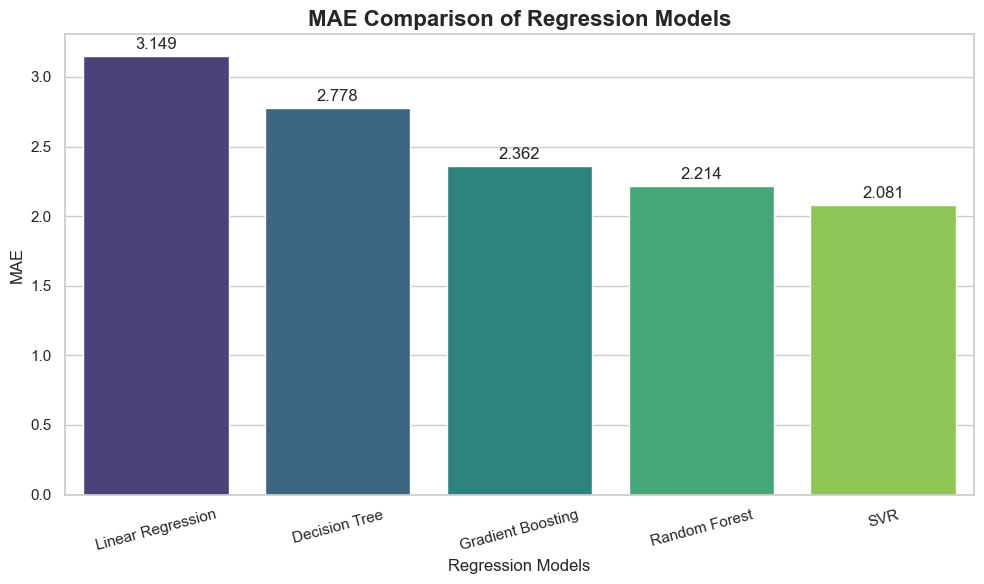

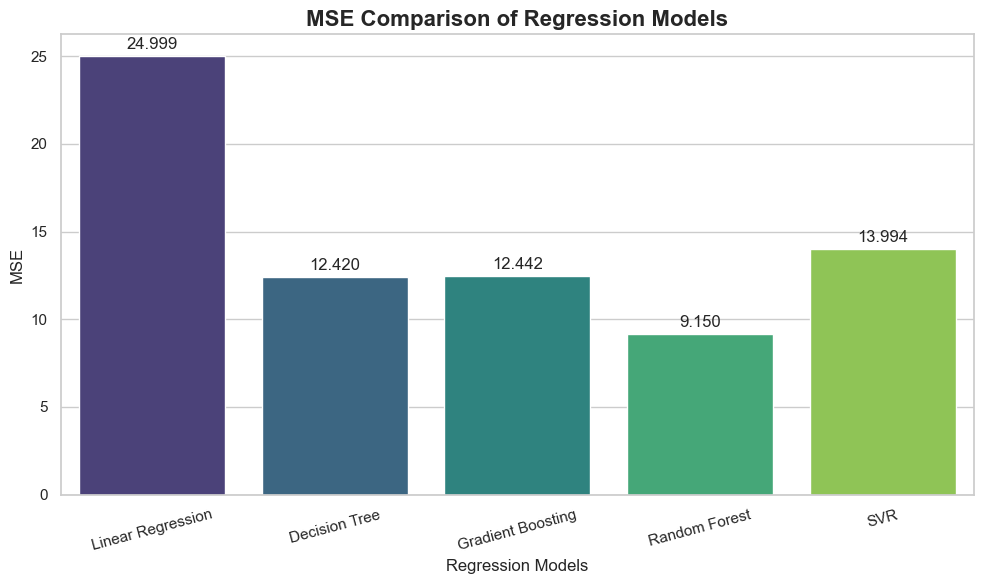

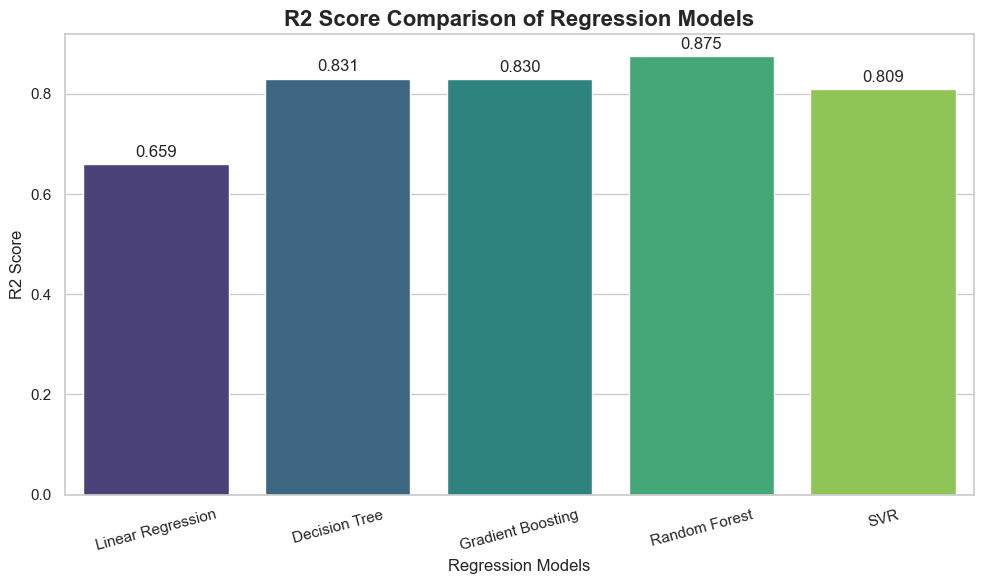

In [105]:

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Gradient Boosting',
        'Random Forest',
        'SVR'
    ],
    'MAE': [3.1487, 2.7776, 2.3624, 2.2140, 2.0810],
    'MSE': [24.9994, 12.4201, 12.4420, 9.1504, 13.9944],
    'R2 Score': [0.6591, 0.8306, 0.8303, 0.8752, 0.8092]
})

sns.set_theme(style="whitegrid")

metrics = ['MAE', 'MSE', 'R2 Score']

for metric in metrics:
    plt.figure(figsize=(10, 6))

    ax = sns.barplot(
        data=results,
        x='Model',
        y=metric,
        hue='Model',
        palette='viridis',
        legend=False
    )

    plt.title(f'{metric} Comparison of Regression Models',
              fontsize=16, fontweight='bold')
    plt.xlabel('Regression Models', fontsize=12)
    plt.ylabel(metric, fontsize=12)
    plt.xticks(rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3)

    plt.tight_layout()
    plt.savefig(f'{metric}_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

# Conclusion

Random Forest is selected as the best overall model for this project because it achieves the **lowest MSE (9.150)** and the **highest R? (0.875)**, while also maintaining a low **MAE of 2.214**. These results indicate the strongest combined performance across average error, sensitivity to larger errors, and explained variance.

SVR achieves the **lowest MAE (2.081)**, so it produces the smallest average absolute error. However, its higher MSE (**13.994**) and lower R? (**0.809**) make Random Forest the stronger overall choice for this submission. The model selection is based on the observed test-set results and should be confirmed further with cross-validation or additional tuning in a future iteration.
